## M5 — Visualizaciones
Generamos el mapa interactivo y los gráficos para la presentación.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import warnings
warnings.filterwarnings('ignore')

RUTA_BASE = r'C:\Users\jcrs2\Documents\Akademia\akademia-residencias'

top100 = pd.read_csv(rf'{RUTA_BASE}\outputs\top100_con_clusters.csv', encoding='utf-8-sig')
df     = pd.read_csv(rf'{RUTA_BASE}\outputs\top100_con_clusters.csv', encoding='utf-8-sig')

print(f"Top 100 cargado: {len(top100)} ubicaciones")
print(f"Ubicaciones cargadas: {df.shape[0]}")
print(f"Perfiles: {df['perfil'].unique().tolist()}")

Top 100 cargado: 87 ubicaciones
Ubicaciones cargadas: 87
Perfiles: ['Zona envejecida — solvencia ajustada', 'Zona premium — máxima solvencia', 'Gran ciudad — mercado masivo', 'Ciudad media — mercado relevante']


### Paso 1 — Mapa interactivo con las 100 ubicaciones

In [30]:
# Color por perfil
colores = {
    "Zona premium — máxima solvencia":         "red",
    "Gran ciudad — mercado masivo":            "blue",
    "Ciudad media — mercado relevante":        "green",
    "Zona envejecida — solvencia ajustada":    "orange"
}

# Crear mapa centrado en España
mapa = folium.Map(
    location=[40.4, -3.7],
    zoom_start=6,
    tiles='CartoDB positron'
)

# Añadir un marcador por municipio
for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row['latitud'], row['longitud']],
        radius=8,
        color=colores[row['perfil']],
        fill=True,
        fill_color=colores[row['perfil']],
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>{row['NOMBRE']}</b><br>
            Posición: #{int(row['posicion_final'])}<br>
            F-of-M: {row['fofm_medio']:.3f}<br>
            Renta hogar: {int(row['renta_hogar']):,}€<br>
            Mayores 75+: {int(row['vol_75plus_total']):,}<br>
            Perfil: {row['perfil']}
            """,
            max_width=250
        ),
        tooltip=row['NOMBRE']
    ).add_to(mapa)

# Leyenda
leyenda = """
<div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
     background: white; padding: 12px; border-radius: 8px;
     border: 1px solid #ccc; font-size: 13px; font-family: Arial">
  <b>Perfiles estratégicos</b><br>
  <span style="color:red">●</span> Zona premium<br>
  <span style="color:blue">●</span> Gran ciudad<br>
  <span style="color:green">●</span> Ciudad media<br>
  <span style="color:orange">●</span> Solvencia ajustada
</div>
"""
mapa.get_root().html.add_child(folium.Element(leyenda))

# Guardar
mapa.save(rf'{RUTA_BASE}\outputs\mapa_top100.html')
print("mapa_top100.html generado — ábrelo en el navegador")

mapa_top100.html generado — ábrelo en el navegador


### Paso 2 — Gráfico de distribución por perfil

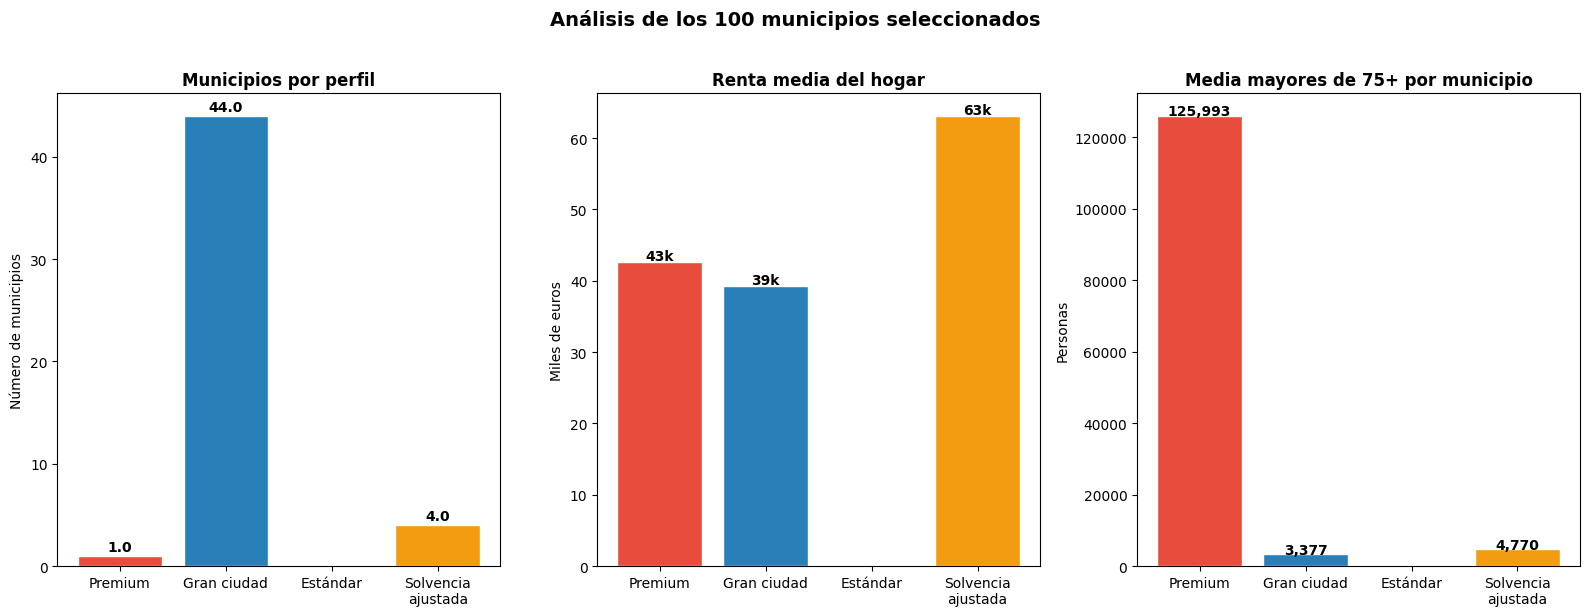

grafico_perfiles.png guardado


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Análisis de los 100 municipios seleccionados',
             fontsize=14, fontweight='bold', y=1.02)

colores_plot = {
    "Zona premium — máxima solvencia":         "#E74C3C",
    "Gran ciudad — mercado masivo":            "#2980B9",
    "Ciudad media — mercado relevante":        "#27AE60",
    "Zona envejecida — solvencia ajustada":    "#F39C12"
}

etiquetas_cortas = {
    "Zona premium — máxima solvencia":         "Premium",
    "Gran ciudad — mercado masivo":            "Gran ciudad",
    "Ciudad media — mercado relevante":        "Ciudad media",
    "Zona envejecida — solvencia ajustada":    "Solvencia\najustada"
}

df['perfil_corto'] = df['perfil'].map(etiquetas_cortas)
orden = ["Premium", "Gran ciudad", "Estándar", "Solvencia\najustada"]
colores_lista = ["#E74C3C", "#2980B9", "#27AE60", "#F39C12"]

# Gráfico 1 — Número de municipios por perfil
conteo = df['perfil_corto'].value_counts().reindex(orden)
axes[0].bar(orden, conteo.values, color=colores_lista, edgecolor='white')
axes[0].set_title('Municipios por perfil', fontweight='bold')
axes[0].set_ylabel('Número de municipios')
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

# Gráfico 2 — Renta media por perfil
renta = df.groupby('perfil_corto')['renta_hogar'].mean().reindex(orden)
axes[1].bar(orden, renta.values / 1000, color=colores_lista, edgecolor='white')
axes[1].set_title('Renta media del hogar', fontweight='bold')
axes[1].set_ylabel('Miles de euros')
for i, v in enumerate(renta.values):
    axes[1].text(i, v/1000 + 0.3, f"{v/1000:.0f}k", ha='center', fontweight='bold')

# Gráfico 3 — Volumen de mayores 75+ por perfil
vol = df.groupby('perfil_corto')['vol_75plus_total'].mean().reindex(orden)
axes[2].bar(orden, vol.values, color=colores_lista, edgecolor='white')
axes[2].set_title('Media mayores de 75+ por municipio', fontweight='bold')
axes[2].set_ylabel('Personas')
for i, v in enumerate(vol.values):
    axes[2].text(i, v + 100, f"{v:,.0f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(rf'{RUTA_BASE}\outputs\grafico_perfiles.png', dpi=150, bbox_inches='tight')
plt.show()
print("grafico_perfiles.png guardado")

### Paso 3 — Gráfico de ranking top 20

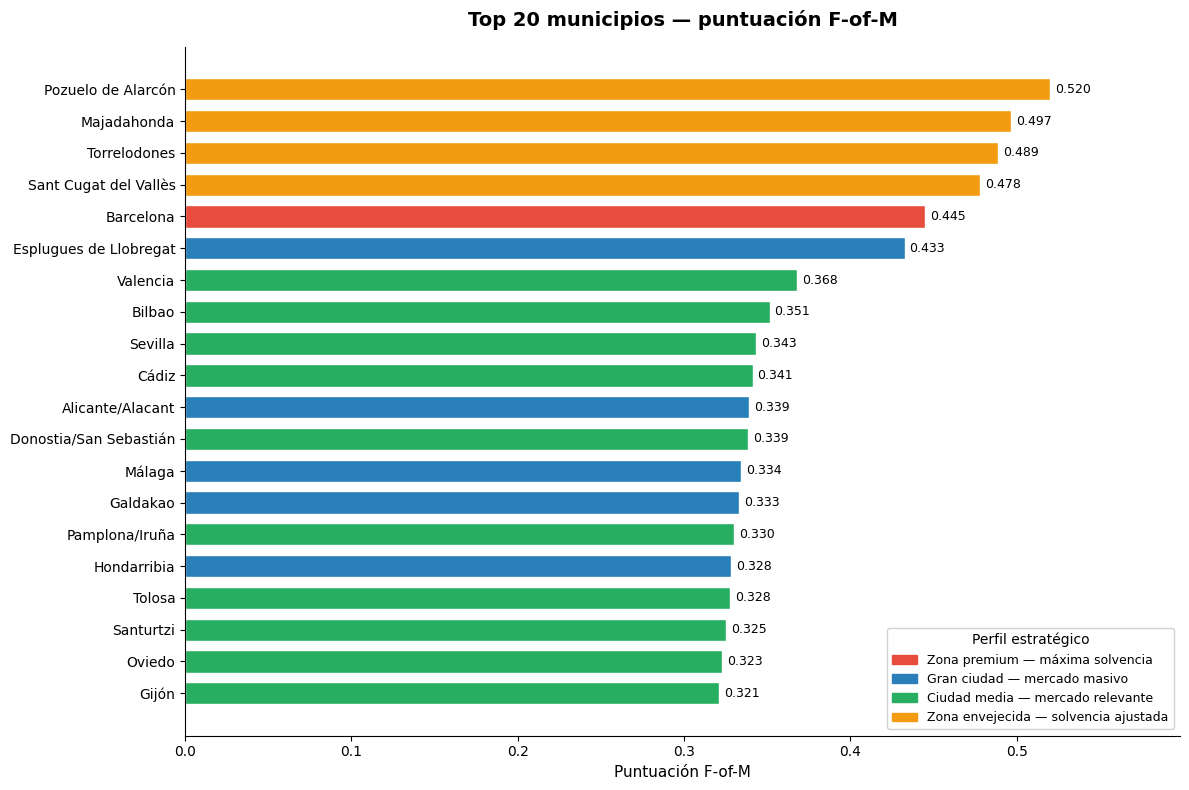

grafico_top20.png guardado


In [32]:
top20 = df.nsmallest(20, 'posicion_final').sort_values('fofm_medio')

colores_barras = [colores_plot[p] for p in top20['perfil']]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(top20['NOMBRE'], top20['fofm_medio'],
               color=colores_barras, edgecolor='white', height=0.7)

# Etiquetas con puntuación
for bar, val in zip(bars, top20['fofm_medio']):
    ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)

ax.set_title('Top 20 municipios — puntuación F-of-M',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Puntuación F-of-M', fontsize=11)
ax.set_xlim(0, top20['fofm_medio'].max() * 1.15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Leyenda
leyenda = [mpatches.Patch(color=c, label=l)
           for l, c in colores_plot.items()]
ax.legend(handles=leyenda, loc='lower right', fontsize=9,
          framealpha=0.9, title='Perfil estratégico')

plt.tight_layout()
plt.savefig(rf'{RUTA_BASE}\outputs\grafico_top20.png', dpi=150, bbox_inches='tight')
plt.show()
print("grafico_top20.png guardado")

### Paso 4 — Gráfico de viabilidad económica

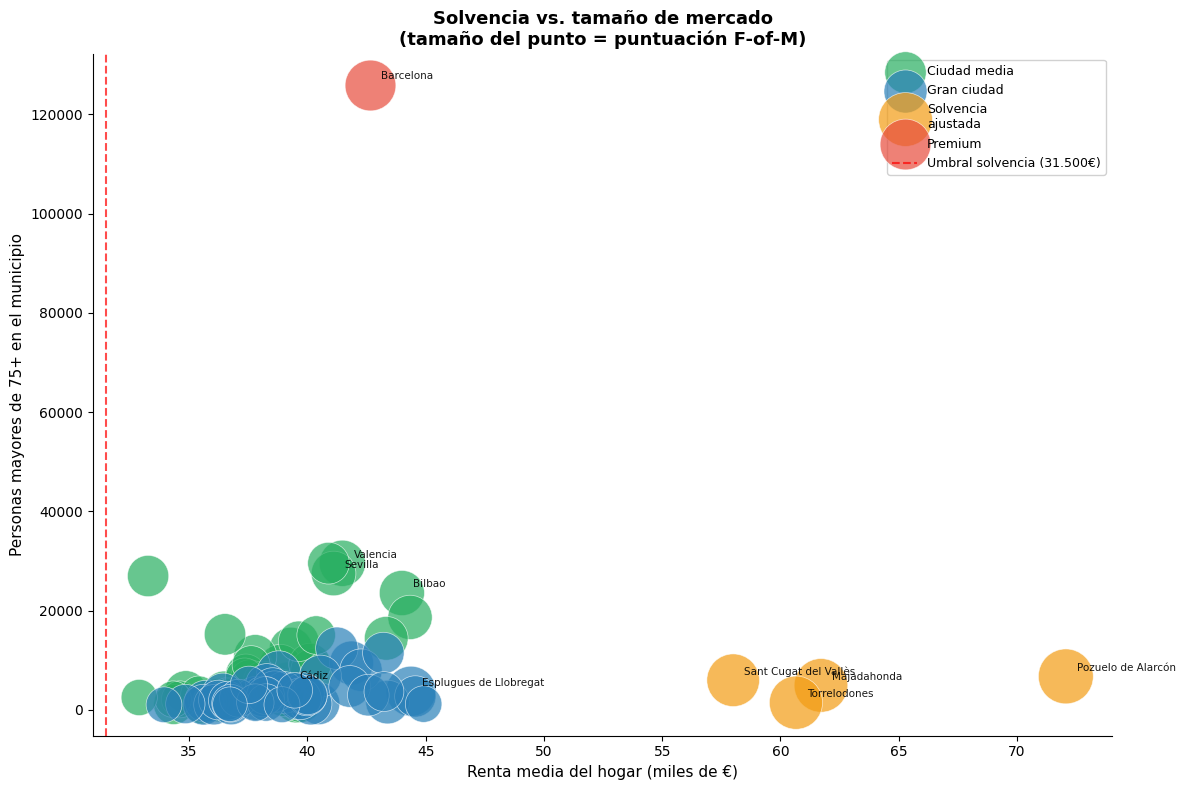

grafico_solvencia_mercado.png guardado


In [33]:
fig, ax = plt.subplots(figsize=(12, 8))

for perfil, grupo in df.groupby('perfil'):
    ax.scatter(
        grupo['renta_hogar'] / 1000,
        grupo['vol_75plus_total'],
        s=grupo['fofm_medio'] * 3000,
        c=colores_plot[perfil],
        alpha=0.7,
        edgecolors='white',
        linewidth=0.5,
        label=etiquetas_cortas[perfil]
    )

# Línea de umbral de solvencia
ax.axvline(x=31.5, color='red', linestyle='--',
           linewidth=1.5, alpha=0.7, label='Umbral solvencia (31.500€)')

# Etiquetar los 10 mejores
top10 = df.nsmallest(10, 'posicion_final')
for _, row in top10.iterrows():
    ax.annotate(
        row['NOMBRE'],
        xy=(row['renta_hogar']/1000, row['vol_75plus_total']),
        xytext=(8, 4), textcoords='offset points',
        fontsize=7.5, alpha=0.9
    )

ax.set_xlabel('Renta media del hogar (miles de €)', fontsize=11)
ax.set_ylabel('Personas mayores de 75+ en el municipio', fontsize=11)
ax.set_title('Solvencia vs. tamaño de mercado\n(tamaño del punto = puntuación F-of-M)',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(rf'{RUTA_BASE}\outputs\grafico_solvencia_mercado.png', dpi=150, bbox_inches='tight')
plt.show()
print("grafico_solvencia_mercado.png guardado")

### Paso 5 — Guardar todo y cerrar el M5

In [34]:
df_muni      = pd.read_csv(rf'{RUTA_BASE}\outputs\ranking_municipios.csv', encoding='utf-8-sig')
resumen_prov = pd.read_csv(rf'{RUTA_BASE}\outputs\resumen_provincias.csv', encoding='utf-8-sig')

with pd.ExcelWriter(rf'{RUTA_BASE}\outputs\resultados_akademia.xlsx', engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Top 100 ubicaciones', index=False)
    df_muni.head(500).to_excel(writer, sheet_name='Ranking municipios', index=False)
    resumen_prov.to_excel(writer, sheet_name='Resumen por provincia', index=False)

    resumen_clusters = df.groupby('perfil').agg(
        municipios  = ('NOMBRE', 'count'),
        renta_media = ('renta_hogar', 'mean'),
        vol_75plus  = ('vol_75plus_total', 'mean'),
        fofm_medio  = ('fofm_medio', 'mean')
    ).round(2).reset_index()
    resumen_clusters.to_excel(writer, sheet_name='Perfiles estratégicos', index=False)

    guia = pd.DataFrame({
        'Archivo': [
            'mapa_top100.html',
            'grafico_perfiles.png',
            'grafico_top20.png',
            'grafico_solvencia_mercado.png',
            'resultados_akademia.xlsx',
            'top100_con_clusters.csv',
            'dataset_maestro.csv'
        ],
        'Para qué sirve': [
            'Mapa interactivo — abrir en navegador, clicar en cada punto',
            'Gráfico de barras con los 4 perfiles estratégicos — meter en slides',
            'Ranking visual del top 20 municipios — meter en slides',
            'Scatter solvencia vs mercado — meter en slides',
            'Excel con todas las pestañas de resultados',
            'Datos completos del top 100 con perfil asignado',
            'Dataset central con todas las variables calculadas'
        ]
    })
    guia.to_excel(writer, sheet_name='Guía de archivos', index=False)

print("=== M5 COMPLETADO ===")
print("\nArchivos generados:")
print("  mapa_top100.html")
print("  grafico_perfiles.png")
print("  grafico_top20.png")
print("  grafico_solvencia_mercado.png")
print("  resultados_akademia.xlsx (5 pestañas)")

=== M5 COMPLETADO ===

Archivos generados:
  mapa_top100.html
  grafico_perfiles.png
  grafico_top20.png
  grafico_solvencia_mercado.png
  resultados_akademia.xlsx (5 pestañas)


In [35]:
# Verificación rápida del resultado final
print("=== VERIFICACIÓN FINAL COMPLETA ===")
print(f"\nTop 100 ubicaciones:")
print(f"  Provincias cubiertas: {top100['CPRO'].nunique()}")
print(f"  Perfiles distintos:   {top100['perfil'].nunique()}")
print(f"  fofm_medio máximo:    {top100['fofm_medio'].max():.4f}")
print(f"  fofm_medio mínimo:    {top100['fofm_medio'].min():.4f}")
print(f"  Municipios por perfil:\n{top100['perfil'].value_counts().to_string()}")

print(f"\nTop 10 final:")
print(top100[['posicion_final','NOMBRE','renta_hogar',
              'vol_75plus_total','perfil']].head(10).to_string(index=False))

=== VERIFICACIÓN FINAL COMPLETA ===

Top 100 ubicaciones:
  Provincias cubiertas: 52
  Perfiles distintos:   4
  fofm_medio máximo:    0.5202
  fofm_medio mínimo:    0.2073
  Municipios por perfil:
perfil
Gran ciudad — mercado masivo            44
Ciudad media — mercado relevante        38
Zona envejecida — solvencia ajustada     4
Zona premium — máxima solvencia          1

Top 10 final:
 posicion_final                 NOMBRE  renta_hogar  vol_75plus_total                               perfil
              1     Pozuelo de Alarcón 72063.659574            6740.0 Zona envejecida — solvencia ajustada
              2            Majadahonda 61711.738095            4927.0 Zona envejecida — solvencia ajustada
              3           Torrelodones 60655.000000            1446.0 Zona envejecida — solvencia ajustada
              4  Sant Cugat del Vallès 57999.490196            5967.0 Zona envejecida — solvencia ajustada
              5              Barcelona 42624.976190          125993.0    